<a href="https://colab.research.google.com/github/Nabilsultan222/Oxford-Pet-Segmentation-Classification-U-Net-vs.-Attention-U-Net-/blob/main/Oxford_Pet_Segmentation_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/segmentation_project"
os.makedirs(SAVE_DIR, exist_ok=True)


Step 1: Download & Organize Dataset


In [ ]:
# Download dataset
!wget https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz

# Extract files
!tar -xzf images.tar.gz
!tar -xzf annotations.tar.gz

# Create clean project structure
import os
import shutil

# --- FIX: Remove dataset directory if it exists to prevent 'already exists' errors on re-run ---
if os.path.exists("dataset"):
    shutil.rmtree("dataset")

os.makedirs("dataset/images", exist_ok=True)
os.makedirs("dataset/masks", exist_ok=True)
os.makedirs("dataset/annotations", exist_ok=True)

# Move images
for file in os.listdir("images"):
    shutil.move(os.path.join("images", file), "dataset/images")

# Move masks (trimaps are masks)
for file in os.listdir("annotations/trimaps"):
    shutil.move(os.path.join("annotations/trimaps", file), "dataset/masks")

# Move annotation files (optional)
for file in os.listdir("annotations"):
    if file != "trimaps":
        src = os.path.join("annotations", file)
        dst = os.path.join("dataset/annotations", file)
        if os.path.isdir(src):
            shutil.move(src, dst)

# Remove leftover folders
shutil.rmtree("images")
shutil.rmtree("annotations")

# --- NEW: Explicitly remove .mat files from dataset/images ---
for file in os.listdir("dataset/images"):
    if file.endswith('.mat'):
        print(f"WARNING: Removing unexpected .mat file from dataset/images: {file}")
        os.remove(os.path.join("dataset/images", file))

print("✅ Dataset downloaded and organized successfully!")

--2026-05-04 02:04:58--  https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
Resolving www.robots.ox.ac.uk (www.robots.ox.ac.uk)... 129.67.94.2
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://thor.robots.ox.ac.uk/pets/images.tar.gz [following]
--2026-05-04 02:04:59--  https://thor.robots.ox.ac.uk/pets/images.tar.gz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 791918971 (755M) [application/octet-stream]
Saving to: ‘images.tar.gz’

images.tar.gz       100%[===================>] 755.23M  21.7MB/s    in 36s     

2026-05-04 02:05:36 (21.0 MB/s) - ‘images.tar.gz’ saved [791918971/791918971]

--2026-05-04 02:05:36--  https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
Resolving www.r

Step 2: Custom Dataset Class (PyTorch)

In [ ]:
# ================================
# Step 2: Custom Dataset Class (PyTorch)
# ================================

import os
from PIL import Image
import torch
from torch.utils.data import Dataset
import torchvision.transforms as T

class OxfordPetDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform

        # Filter for only .jpg files
        all_files = os.listdir(image_dir)
        self.image_files = sorted([f for f in all_files if f.endswith('.jpg')])
        print(f"DEBUG: Loaded {len(self.image_files)} .jpg files from {image_dir}")
        if any(f.endswith('.mat') for f in all_files):
            print(f"DEBUG: Found .mat files in {image_dir}, ensuring they are filtered.")

        # Create class mapping from filenames
        self.classes = sorted(list(set([f.split('_')[0] for f in self.image_files])))
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]

        # Image path
        img_path = os.path.join(self.image_dir, img_name)

        # Mask path (same name but .png)
        mask_name = img_name.replace(".jpg", ".png")
        mask_path = os.path.join(self.mask_dir, mask_name)

        # --- NEW: Debug print for image path ---
        print(f"DEBUG: Attempting to open image: {img_path}")

        # Load image and mask
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # Extract label from filename
        class_name = img_name.split('_')[0]
        label = self.class_to_idx[class_name]

        # Apply transforms
        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return image, mask, label


# Example transforms
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor() # model compatibility
])

# Create dataset
dataset = OxfordPetDataset(
    image_dir="dataset/images",
    mask_dir="dataset/masks",
    transform=transform
)

print("✅ Dataset loaded successfully!")
print("Total samples:", len(dataset))
print("Total classes:", len(dataset.classes))


DEBUG: Loaded 7390 .jpg files from dataset/images
✅ Dataset loaded successfully!
Total samples: 7390
Total classes: 35


Step 3: Fix Mask Labels

In [ ]:
# ================================
# Step 3: Fix Mask Labels
# ================================
# Original trimap values:
# 1 = pet (foreground)
# 2 = background
# 3 = boundary

# We convert:
# 1 (pet) -> 1
# 3 (boundary) -> 1
# 2 (background) -> 0
# binary format by merging boundary and foreground into a single class

import numpy as np

class OxfordPetDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform

        # Filter for only .jpg files
        all_files = os.listdir(image_dir)
        self.image_files = sorted([f for f in all_files if f.endswith('.jpg')])
        print(f"DEBUG: Loaded {len(self.image_files)} .jpg files from {image_dir}")
        if any(f.endswith('.mat') for f in all_files):
            print(f"DEBUG: Found .mat files in {image_dir}, ensuring they are filtered.")

        self.classes = sorted(list(set([f.split('_')[0] for f in self.image_files])))
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]

        img_path = os.path.join(self.image_dir, img_name)
        mask_name = img_name.replace(".jpg", ".png")
        mask_path = os.path.join(self.mask_dir, mask_name)

        # --- NEW: Debug print for image path ---
        print(f"DEBUG: Attempting to open image: {img_path}")

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # Convert mask to numpy (pixel wise)
        mask = np.array(mask)

        # Fix mask labels
        mask = np.where(mask == 2, 0, 1)   # background=0, pet+boundary=1

        # Convert back to PIL (so transform works)
        mask = Image.fromarray(mask.astype(np.uint8))

        # Label
        class_name = img_name.split('_')[0]
        label = self.class_to_idx[class_name]

        # Apply transforms
        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return image, mask, label


print("✅ Mask labels fixed (background=0, pet=1)")


✅ Mask labels fixed (background=0, pet=1)


Step 4 (Enhanced): Preprocessing + Visualization

Total samples: 7390
Total classes: 35
Class names (first 10): ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British', 'Egyptian', 'Maine', 'Persian', 'Ragdoll', 'Russian']
DEBUG: Attempting to open image: dataset/images/Abyssinian_1.jpg
DEBUG: Attempting to open image: dataset/images/Abyssinian_10.jpg
DEBUG: Attempting to open image: dataset/images/Abyssinian_100.jpg


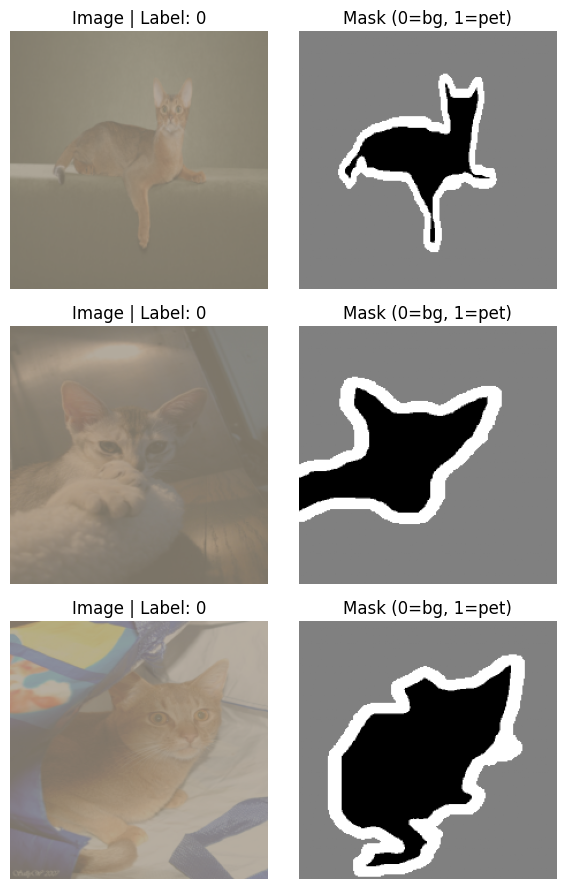

DEBUG: Attempting to open image: dataset/images/Abyssinian_1.jpg
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([1, 224, 224])
Mask unique values: tensor([0.0039, 0.0078, 0.0118])


In [ ]:
# ================================
# Step 4 (Enhanced): Preprocessing + Visualization
# ================================

import matplotlib.pyplot as plt

# Dataset already created above
print("Total samples:", len(dataset))
print("Total classes:", len(dataset.classes))
print("Class names (first 10):", dataset.classes[:10])


def show_samples(dataset, num_samples=3):
    fig, axes = plt.subplots(num_samples, 2, figsize=(6, 3*num_samples))

    for i in range(num_samples):
        image, mask, label = dataset[i]

        # Convert tensor → numpy for display
        img = image.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze().numpy()

        # Undo normalization for visualization
        mean = [0.485, 0.456, 0.406]
        std = [0.229, 0.224, 0.225]
        img = img * std + mean
        img = img.clip(0, 1)

        # Plot image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Image | Label: {label}")
        axes[i, 0].axis("off")

        # Plot mask
        axes[i, 1].imshow(mask_np, cmap="gray")
        axes[i, 1].set_title("Mask (0=bg, 1=pet)")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()


# Run visualization
show_samples(dataset, num_samples=3)



image, mask, label = dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask unique values:", torch.unique(mask))

Step 5: Data Augmentation (Toggle ON/OFF)

DEBUG: Loaded 7390 .jpg files from dataset/images
DEBUG: Loaded 7390 .jpg files from dataset/images
✅ Augmentation pipeline ready!


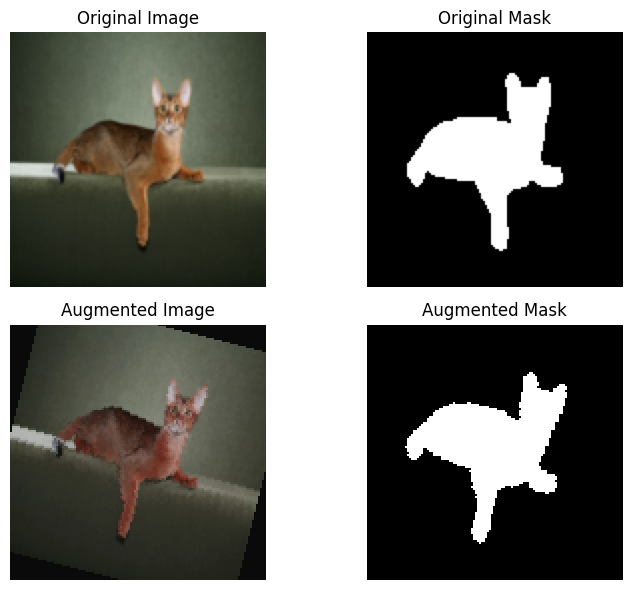

In [ ]:
# ================================
# Step 5: Data Augmentation (Toggle ON/OFF)
# ================================
# artificially creating new training samples by modifying existing data

import random
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

# -------------------------------
# Custom Joint Transform (Image + Mask together)
# -------------------------------
class JointTransform:
    def __init__(self, resize=(128, 128), augment=True):
        self.resize = resize
        self.augment = augment

        # Color jitter ONLY for image
        self.color_jitter = T.ColorJitter(
            brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1
        )

    def __call__(self, image, mask):
        # Resize first
        image = F.resize(image, self.resize)
        mask = F.resize(mask, self.resize, interpolation=T.InterpolationMode.NEAREST)

        if self.augment:
            # Horizontal flip
            if random.random() > 0.5:
                image = F.hflip(image)
                mask = F.hflip(mask)

            # Rotation
            angle = random.uniform(-20, 20)
            image = F.rotate(image, angle)
            mask = F.rotate(mask, angle)

            # Color jitter (ONLY image)
            image = self.color_jitter(image)

        # Convert to tensor
        image = F.to_tensor(image)
        mask = torch.from_numpy(np.array(mask)).unsqueeze(0).float()

        # Normalize image
        image = F.normalize(image,
                            mean=[0.485, 0.456, 0.406],
                            std=[0.229, 0.224, 0.225])

        return image, mask


# ================================
# Update Dataset to use Joint Transform
# ================================

class OxfordPetDataset(Dataset):
    def __init__(self, image_dir, mask_dir, joint_transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.joint_transform = joint_transform

        # Filter for only .jpg files
        all_files = os.listdir(image_dir)
        self.image_files = sorted([f for f in all_files if f.endswith('.jpg')])
        print(f"DEBUG: Loaded {len(self.image_files)} .jpg files from {image_dir}")
        if any(f.endswith('.mat') for f in all_files):
            print(f"DEBUG: Found .mat files in {image_dir}, ensuring they are filtered.")

        self.classes = sorted(list(set([f.split('_')[0] for f in self.image_files])))
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]

        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, img_name.replace(".jpg", ".png"))

        # --- NEW: Debug print for image path ---
        #print(f"DEBUG: Attempting to open image: {img_path}")

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # Fix mask labels
        mask = np.array(mask)
        mask = np.where(mask == 2, 0, 1)
        mask = Image.fromarray(mask.astype(np.uint8))

        # Label
        class_name = img_name.split('_')[0]
        label = self.class_to_idx[class_name]

        # Apply joint transform
        if self.joint_transform:
            image, mask = self.joint_transform(image, mask)

        return image, mask, label


# ================================
# Create datasets (Aug ON / OFF)
# ================================

# WITHOUT augmentation
dataset_no_aug = OxfordPetDataset(
    "dataset/images",
    "dataset/masks",
    joint_transform=JointTransform(augment=False)
)

# WITH augmentation
dataset_aug = OxfordPetDataset(
    "dataset/images",
    "dataset/masks",
    joint_transform=JointTransform(augment=True)
)

print("✅ Augmentation pipeline ready!")


# ================================
# Visualization: Compare Aug vs No Aug
# ================================

def compare_augmentation(dataset1, dataset2, idx=0):
    img1, mask1, _ = dataset1[idx]
    img2, mask2, _ = dataset2[idx]

    def denorm(img):
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
        return (img * std + mean).clamp(0,1)

    img1 = denorm(img1).permute(1,2,0).numpy()
    img2 = denorm(img2).permute(1,2,0).numpy()

    mask1 = mask1.squeeze().numpy()
    mask2 = mask2.squeeze().numpy()

    fig, ax = plt.subplots(2,2, figsize=(8,6))

    ax[0,0].imshow(img1); ax[0,0].set_title("Original Image")
    ax[0,1].imshow(mask1, cmap="gray"); ax[0,1].set_title("Original Mask")

    ax[1,0].imshow(img2); ax[1,0].set_title("Augmented Image")
    ax[1,1].imshow(mask2, cmap="gray"); ax[1,1].set_title("Augmented Mask")

    for a in ax.flatten():
        a.axis("off")

    plt.tight_layout()
    plt.show()


# Run comparison
compare_augmentation(dataset_no_aug, dataset_aug, idx=0)


Step 6: Train / Val / Test Split

Total: 7390
Train: 5173
Val:   1108
Test:  1109
✅ DataLoaders ready!
Batch image shape: torch.Size([64, 3, 128, 128])
Batch mask shape: torch.Size([64, 1, 128, 128])
Batch labels shape: torch.Size([64])


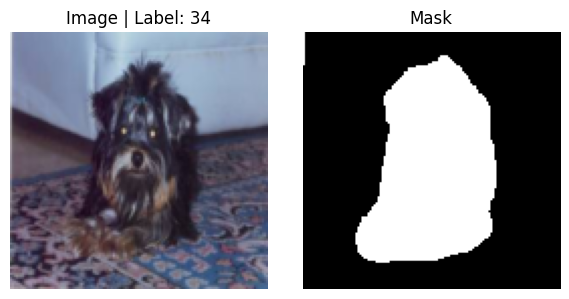

In [ ]:
# ================================
# Step 6: Train / Val / Test Split
# ================================

from torch.utils.data import random_split, DataLoader
import torch

# Reproducibility
torch.manual_seed(42)

# Use dataset with augmentation for training
full_dataset = dataset_aug

# Split sizes
total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size   = int(0.15 * total_size)
test_size  = total_size - train_size - val_size

# Split dataset
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

print(f"Total: {total_size}")
print(f"Train: {len(train_dataset)}")
print(f"Val:   {len(val_dataset)}")
print(f"Test:  {len(test_dataset)}")


# ================================
# IMPORTANT: Disable augmentation for Val/Test
# ================================

# Create a no-augmentation transform
no_aug_transform = JointTransform(augment=False)

# Replace transforms for val/test
val_dataset.dataset.joint_transform = no_aug_transform
test_dataset.dataset.joint_transform = no_aug_transform


# ================================
# Create DataLoaders
# ================================

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

print("✅ DataLoaders ready!")


# ================================
# Quick Batch Check (VERY IMPORTANT)
# ================================

images, masks, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)   # (B, 3, H, W)
print("Batch mask shape:", masks.shape)     # (B, 1, H, W)
print("Batch labels shape:", labels.shape)  # (B,)


# ================================
# Visualize one batch sample
# ================================

import matplotlib.pyplot as plt

def show_batch_sample(images, masks, labels, idx=0):
    img = images[idx]
    mask = masks[idx]

    # Denormalize image
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img = (img * std + mean).clamp(0,1)

    img = img.permute(1,2,0).numpy()
    mask = mask.squeeze().numpy()

    plt.figure(figsize=(6,3))

    plt.subplot(1,2,1)
    plt.imshow(img)
    plt.title(f"Image | Label: {labels[idx].item()}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(mask, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Run visualization
show_batch_sample(images, masks, labels)


Step 7: Visualization Function (3x3 Grid with Mask Overlay)

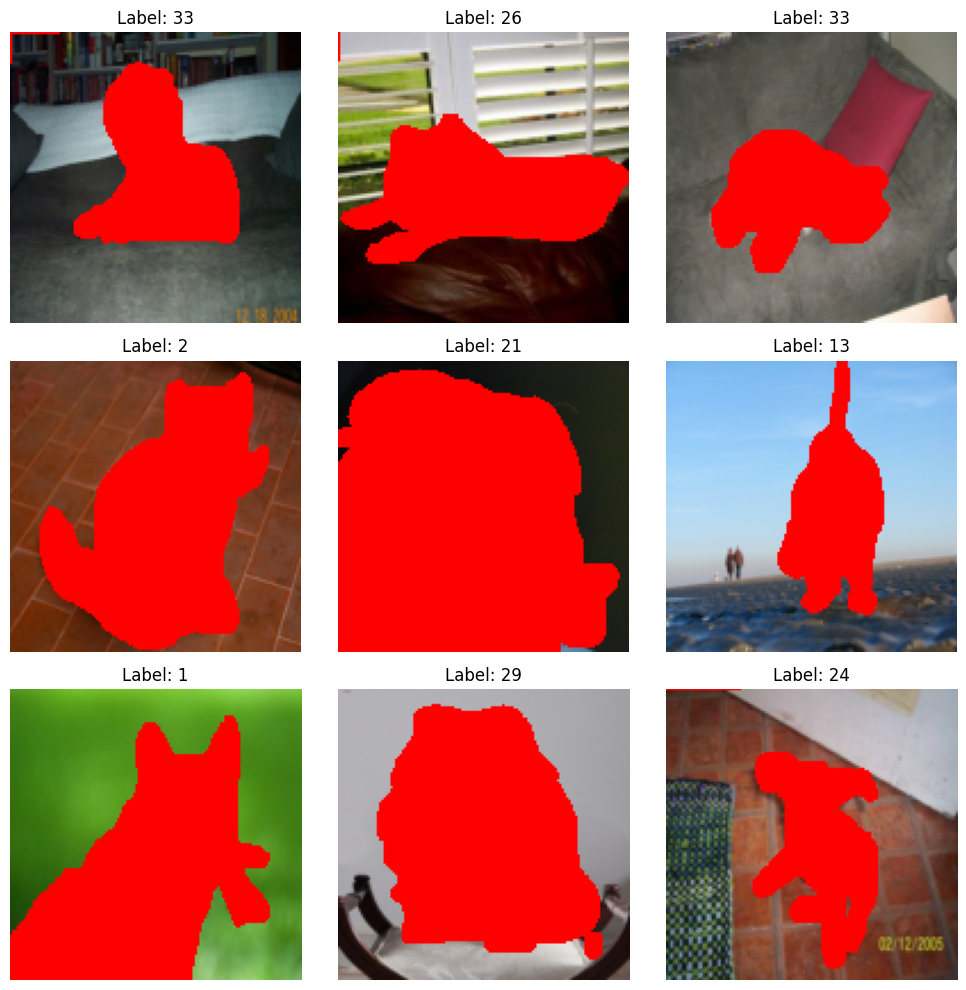

In [ ]:
# ================================
# Step 7: Visualization Function (3x3 Grid with Mask Overlay)
# ================================

import random
import matplotlib.pyplot as plt
import torch

def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (img * std + mean).clamp(0,1)

def show_3x3_overlay(dataset):
    indices = random.sample(range(len(dataset)), 9)

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))

    for i, idx in enumerate(indices):
        image, mask, label = dataset[idx]

        # Denormalize image
        image = denormalize(image).permute(1,2,0).numpy()
        mask = mask.squeeze().numpy()

        # Create overlay (red mask)
        overlay = image.copy()
        overlay[mask > 0.5] = [1, 0, 0]  # red color

        ax = axes[i // 3, i % 3]
        ax.imshow(overlay)
        ax.set_title(f"Label: {label}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Run visualization (use non-aug dataset for cleaner view)
show_3x3_overlay(dataset_no_aug)

Step 8: Build U-Net Model

In [ ]:
# ================================
# Step 8: Build U-Net Model
# ================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# -------------------------------
# Basic Conv Block
# -------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# -------------------------------
# Down Block (Encoder)
# -------------------------------
class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x


# -------------------------------
# Up Block (Decoder)
# -------------------------------
class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x1, x2):
        x1 = self.up(x1)

        # Match size (in case of mismatch)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])

        # Skip connection
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


# -------------------------------
# U-Net Model
# -------------------------------
class UNet(nn.Module):
    def __init__(self, n_classes=1):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(3, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # Bottleneck
        self.bottleneck = Down(512, 1024)

        # Decoder
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)

        # Output layer
        self.outc = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        x1 = self.inc(x)       # 64
        x2 = self.down1(x1)    # 128
        x3 = self.down2(x2)    # 256
        x4 = self.down3(x3)    # 512

        # Bottleneck
        x5 = self.bottleneck(x4)  # 1024

        # Decoder with skip connections
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Output segmentation mask
        logits = self.outc(x)
        return logits


# ================================
# Model Test (VERY IMPORTANT)
# ================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(n_classes=1).to(device)

# Dummy input test
x = torch.randn(1, 3, 224, 224).to(device)
y = model(x)

print("Input shape :", x.shape)
print("Output shape:", y.shape)   # should be (1, 1, 224, 224)

Input shape : torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 1, 224, 224])


Step 9: U-Net + Classification Head

In [ ]:
# ================================
# Step 9: U-Net + Classification Head
# ================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# -------------------------------
# (Reuse blocks from Step 8)
# -------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x):
        return self.conv(self.pool(x))


class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x1, x2):
        x1 = self.up(x1)

        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])

        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


# -------------------------------
# U-Net + Classifier
# -------------------------------
class UNetWithClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Encoder (extracts features)
        self.inc = DoubleConv(3, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # Bottleneck (used for classification)
        self.bottleneck = Down(512, 1024)

        # Decoder (reconstructs the segmentation mask)
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)

        # Segmentation head
        self.seg_head = nn.Conv2d(64, 1, kernel_size=1)

        # -------------------------------
        # Classification Head
        # -------------------------------
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),  # Global pooling
            nn.Flatten(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Bottleneck
        x5 = self.bottleneck(x4)

        # -------------------------------
        # Classification output
        # -------------------------------
        cls_out = self.classifier(x5)

        # -------------------------------
        # Decoder (Segmentation)
        # -------------------------------
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        seg_out = self.seg_head(x)

        return seg_out, cls_out


# ================================
# Model Test
# ================================

num_classes = len(dataset.classes)

model = UNetWithClassifier(num_classes=num_classes).to(device)

x = torch.randn(2, 3, 224, 224).to(device)
seg_out, cls_out = model(x)

print("Segmentation output shape:", seg_out.shape)  # (B, 1, H, W)
print("Classification output shape:", cls_out.shape)  # (B, num_classes)

Segmentation output shape: torch.Size([2, 1, 224, 224])
Classification output shape: torch.Size([2, 35])


Step 10: Loss Functions

In [ ]:
# ================================
# Step 10: Loss Functions
# ================================

import torch
import torch.nn as nn

# -------------------------------
# Segmentation Losses
# -------------------------------

# BCE Loss (with logits → NO sigmoid before passing)
bce_loss_fn = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(pred, target, smooth=1e-6):
    # Apply sigmoid to predictions
    pred = torch.sigmoid(pred)

    pred = pred.view(-1)
    target = target.view(-1)

    intersection = (pred * target).sum()
    dice = (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)

    return 1 - dice


# Combined Segmentation Loss (better performance)
def segmentation_loss(pred, target):
    bce = bce_loss_fn(pred, target)
    d_loss = dice_loss(pred, target)
    return bce + d_loss


# -------------------------------
# Classification Loss
# -------------------------------
class_loss_fn = nn.CrossEntropyLoss()


# -------------------------------
# Total Loss
# -------------------------------
def total_loss(seg_pred, seg_target, cls_pred, cls_target):
    seg_loss = segmentation_loss(seg_pred, seg_target)
    cls_loss = class_loss_fn(cls_pred, cls_target)

    return seg_loss + cls_loss, seg_loss, cls_loss


# ================================
# Test Loss Functions
# ================================

seg_pred = torch.randn(2, 1, 224, 224)   # model output (logits)
seg_target = torch.randint(0, 2, (2, 1, 224, 224)).float()

cls_pred = torch.randn(2, num_classes)   # logits
cls_target = torch.randint(0, num_classes, (2,))

loss, seg_l, cls_l = total_loss(seg_pred, seg_target, cls_pred, cls_target)

print("Total Loss:", loss.item())
print("Seg Loss:", seg_l.item())
print("Cls Loss:", cls_l.item())


Total Loss: 7.347104549407959
Seg Loss: 1.3082915544509888
Cls Loss: 6.03881311416626


Step 11: Training Loop

In [ ]:
import os

base_drive_dir = "/content/drive/MyDrive/segmentation_project"
os.makedirs(base_drive_dir, exist_ok=True)

✅ Resumed from checkpoint!


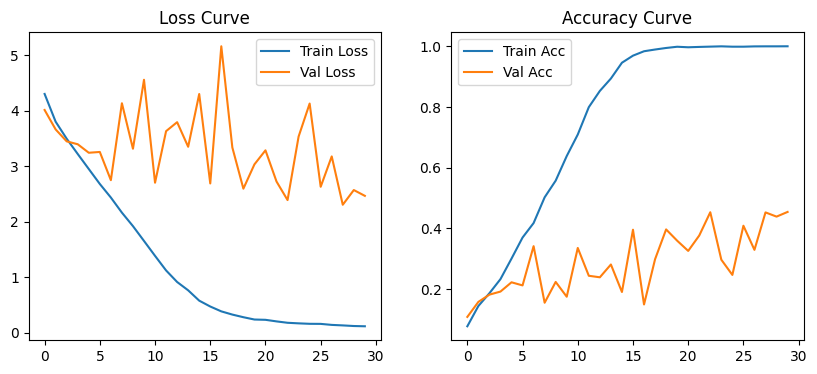

In [ ]:
# ================================
# Step 11: Training Loop
# ================================

import torch
import torchvision.transforms.functional as F
import os
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)

# Define checkpoint paths in Google Drive
unet_drive_dir = os.path.join(base_drive_dir, 'unet')
os.makedirs(unet_drive_dir, exist_ok=True)
checkpoint_path = os.path.join(SAVE_DIR, "unet_checkpoint.pth")
best_model_path = os.path.join(SAVE_DIR, "unet_best.pth")

# -------------------------------
# Resume Training + LOAD HISTORY
# -------------------------------
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint['best_val_acc']

    # 🔥 LOAD HISTORY (IMPORTANT FIX)
    train_losses = checkpoint.get('train_losses', [])
    val_losses = checkpoint.get('val_losses', [])
    train_accs = checkpoint.get('train_accs', [])
    val_accs = checkpoint.get('val_accs', [])

    print("✅ Resumed from checkpoint!")
else:
    start_epoch = 0
    best_val_acc = 0.0

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []


# -------------------------------
# Accuracy
# -------------------------------
def classification_accuracy(pred, target):
    preds = torch.argmax(pred, dim=1)
    correct = (preds == target).sum().item()
    return correct / target.size(0)


# -------------------------------
# Train
# -------------------------------
def train_one_epoch(model, loader, optimizer):
    model.train()

    total_loss_epoch = 0
    total_acc = 0

    for images, masks, labels in tqdm(loader):
        images = images.to(device)
        masks = masks.to(device)
        labels = labels.to(device)

        seg_pred, cls_pred = model(images) # model prediction
        loss, seg_loss, cls_loss = total_loss(seg_pred, masks, cls_pred, labels)

        optimizer.zero_grad()
        loss.backward() #compute gradients
        optimizer.step() # update weights

        total_loss_epoch += loss.item()
        total_acc += classification_accuracy(cls_pred, labels)

    return total_loss_epoch / len(loader), total_acc / len(loader)


# -------------------------------
# Validate
# -------------------------------
def validate(model, loader):
    model.eval()

    total_loss_epoch = 0
    total_acc = 0

    with torch.no_grad():
        for images, masks, labels in loader:
            images = images.to(device)
            masks = masks.to(device)
            labels = labels.to(device)

            seg_pred, cls_pred = model(images)
            loss, seg_loss, cls_loss = total_loss(seg_pred, masks, cls_pred, labels)

            total_loss_epoch += loss.item()
            total_acc += classification_accuracy(cls_pred, labels)

    return total_loss_epoch / len(loader), total_acc / len(loader)


# ================================
# Training Loop
# ================================

num_epochs = 30

for epoch in range(start_epoch, num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
    val_loss, val_acc = validate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print("✅ Best model updated!")

    # 🔥 SAVE EVERYTHING (INCLUDING HISTORY)
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'best_val_acc': best_val_acc,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accs': train_accs,
        'val_accs': val_accs
    }, checkpoint_path)

    print("💾 Checkpoint saved")


# ================================
# Plot Training Curves (FIXED)
# ================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1,2,2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy Curve")

plt.show()

Step 12: Evaluation Metrics

In [ ]:
# ================================
# Step 12: Evaluation Metrics
# ================================

import torch


# -------------------------------
# SEGMENTATION METRICS
# -------------------------------

def iou_score(pred, target, threshold=0.5, eps=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(1,2,3))
    union = (pred + target).sum(dim=(1,2,3)) - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()


def dice_score(pred, target, threshold=0.5, eps=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(1,2,3))
    dice = (2 * intersection + eps) / (pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3)) + eps)

    return dice.mean().item()


def pixel_accuracy(pred, target, threshold=0.5):
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    correct = (pred == target).float().sum()
    total = torch.numel(pred)

    return (correct / total).item()


# -------------------------------
# CLASSIFICATION METRICS
# -------------------------------

def classification_metrics(pred, target, num_classes):
    preds = torch.argmax(pred, dim=1)

    correct = (preds == target).sum().item()
    total = target.size(0)
    accuracy = correct / total

    # Precision, Recall, F1 (macro)
    precision_list = []
    recall_list = []
    f1_list = []

    for cls in range(num_classes):
        tp = ((preds == cls) & (target == cls)).sum().item()
        fp = ((preds == cls) & (target != cls)).sum().item()
        fn = ((preds != cls) & (target == cls)).sum().item()

        precision = tp / (tp + fp + 1e-6)
        recall = tp / (tp + fn + 1e-6)
        f1 = 2 * precision * recall / (precision + recall + 1e-6)

        precision_list.append(precision)
        recall_list.append(recall)
        f1_list.append(f1)

    precision = sum(precision_list) / num_classes
    recall = sum(recall_list) / num_classes
    f1 = sum(f1_list) / num_classes

    return accuracy, precision, recall, f1


# -------------------------------
# FULL EVALUATION FUNCTION
# -------------------------------

def evaluate(model, loader, num_classes):
    model.eval()

    total_iou = 0
    total_dice = 0
    total_pix_acc = 0

    total_acc = 0
    total_prec = 0
    total_rec = 0
    total_f1 = 0

    count = 0

    with torch.no_grad():
        for images, masks, labels in loader:
            images = images.to(device)
            masks = masks.to(device)
            labels = labels.to(device)

            seg_pred, cls_pred = model(images)

            # Segmentation metrics
            total_iou += iou_score(seg_pred, masks)
            total_dice += dice_score(seg_pred, masks)
            total_pix_acc += pixel_accuracy(seg_pred, masks)

            # Classification metrics
            acc, prec, rec, f1 = classification_metrics(cls_pred, labels, num_classes)

            total_acc += acc
            total_prec += prec
            total_rec += rec
            total_f1 += f1

            count += 1

    return {
        "IoU": total_iou / count,
        "Dice": total_dice / count,
        "Pixel Acc": total_pix_acc / count,
        "Cls Acc": total_acc / count,
        "Precision": total_prec / count,
        "Recall": total_rec / count,
        "F1": total_f1 / count
    }


# ================================
# Run Evaluation
# ================================

num_classes = len(dataset.classes)

train_metrics = evaluate(model, train_loader, num_classes)
val_metrics   = evaluate(model, val_loader, num_classes)
test_metrics  = evaluate(model, test_loader, num_classes)


# Print results
def print_metrics(name, metrics):
    print(f"\n{name} Metrics:")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")

print_metrics("Train", train_metrics)
print_metrics("Validation", val_metrics)
print_metrics("Test", test_metrics)


Train Metrics:
IoU: 0.9400
Dice: 0.9675
Pixel Acc: 0.9782
Cls Acc: 1.0000
Precision: 0.8268
Recall: 0.8268
F1: 0.8268

Validation Metrics:
IoU: 0.7969
Dice: 0.8769
Pixel Acc: 0.9091
Cls Acc: 0.4540
Precision: 0.3735
Recall: 0.3761
F1: 0.3400

Test Metrics:
IoU: 0.7903
Dice: 0.8726
Pixel Acc: 0.9086
Cls Acc: 0.4849
Precision: 0.3851
Recall: 0.3826
F1: 0.3561


Step 13: Prediction Function

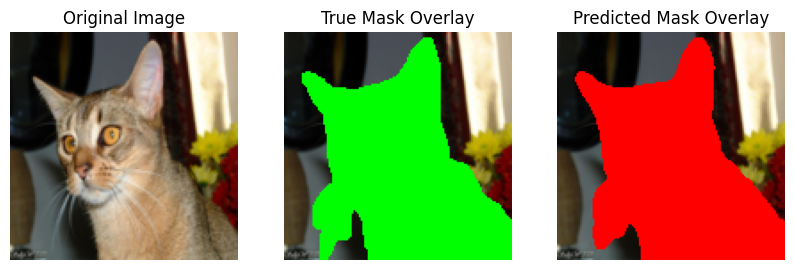

True Class: Abyssinian
Predicted Class: Abyssinian
IoU Score: 0.9603


In [ ]:
# ================================
# Step 13: Prediction Function
# ================================

import matplotlib.pyplot as plt
import torch
import numpy as np

def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (img * std + mean).clamp(0,1)


def predict_and_visualize(model, dataset, idx):
    model.eval()

    image, mask, label = dataset[idx]

    with torch.no_grad():
        img_input = image.unsqueeze(0).to(device)
        seg_pred, cls_pred = model(img_input)

        # Segmentation prediction
        pred_mask = torch.sigmoid(seg_pred).cpu().squeeze().numpy()
        pred_mask = (pred_mask > 0.5).astype(np.uint8)

        # True mask
        true_mask = mask.squeeze().numpy()

        # Classification prediction
        pred_class = torch.argmax(cls_pred, dim=1).item()
        true_class = label

        # IoU calculation
        intersection = np.logical_and(pred_mask, true_mask).sum()
        union = np.logical_or(pred_mask, true_mask).sum()
        iou = intersection / (union + 1e-6)

    # Prepare images
    img = denormalize(image).permute(1,2,0).numpy()

    # Overlay masks
    true_overlay = img.copy()
    true_overlay[true_mask > 0.5] = [0, 1, 0]  # green

    pred_overlay = img.copy()
    pred_overlay[pred_mask > 0.5] = [1, 0, 0]  # red

    # Plot
    plt.figure(figsize=(10,4))

    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(true_overlay)
    plt.title("True Mask Overlay")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(pred_overlay)
    plt.title("Predicted Mask Overlay")
    plt.axis("off")

    plt.show()

    # Print results
    print("True Class:", dataset.classes[true_class])
    print("Predicted Class:", dataset.classes[pred_class])
    print(f"IoU Score: {iou:.4f}")


# ================================
# Run Prediction Example
# ================================

predict_and_visualize(model, dataset_no_aug, idx=10)

Step 14: Attention U-Net + Classification Head

In [ ]:
# ================================
# Step 14: Attention U-Net + Classification Head
# ================================
# Skip connections are now filtered using attention
# Model focuses on important regions only

import torch
import torch.nn as nn
import torch.nn.functional as F


# -------------------------------
# Double Conv
# -------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# -------------------------------
# Attention Gate
# -------------------------------
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )

        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )

        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)

        psi = self.relu(g1 + x1)
        psi = self.psi(psi)

        return x * psi


# -------------------------------
# Down Block
# -------------------------------
class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x):
        return self.conv(self.pool(x))


# -------------------------------
# Up Block with Attention
# -------------------------------
class UpAtt(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.att = AttentionGate(F_g=in_ch // 2, F_l=in_ch // 2, F_int=in_ch // 4)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x1, x2):
        x1 = self.up(x1)

        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])

        # Apply attention on skip connection
        x2 = self.att(x1, x2)

        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


# -------------------------------
# Attention U-Net + Classifier
# -------------------------------
class AttentionUNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(3, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # Bottleneck
        self.bottleneck = Down(512, 1024)

        # Decoder with Attention
        self.up1 = UpAtt(1024, 512)
        self.up2 = UpAtt(512, 256)
        self.up3 = UpAtt(256, 128)
        self.up4 = UpAtt(128, 64)

        # Segmentation head
        self.seg_head = nn.Conv2d(64, 1, kernel_size=1)

        # Classification head
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)),
            nn.Flatten(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Bottleneck
        x5 = self.bottleneck(x4)

        # Classification output
        cls_out = self.classifier(x5)

        # Decoder with attention
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        seg_out = self.seg_head(x)

        return seg_out, cls_out


# ================================
# Test Model
# ================================

model_att = AttentionUNet(num_classes=len(dataset.classes)).to(device)

x = torch.randn(2, 3, 224, 224).to(device)
seg_out, cls_out = model_att(x)

print("Seg shape:", seg_out.shape)
print("Cls shape:", cls_out.shape)

Seg shape: torch.Size([2, 1, 224, 224])
Cls shape: torch.Size([2, 35])


Step 15: Train Attention U-Net

✅ Resumed Attention U-Net!


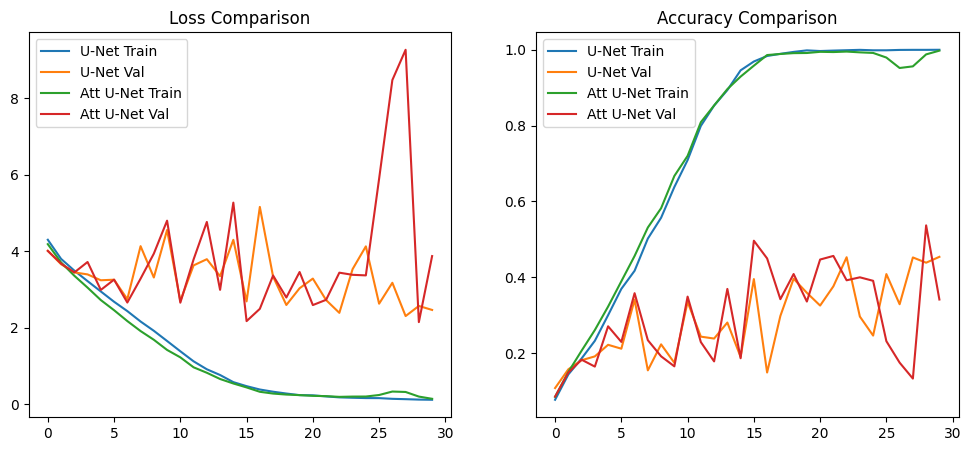


Attention U-Net Train Metrics:
IoU: 0.9235
Dice: 0.9580
Pixel Acc: 0.9721
Cls Acc: 0.8451
Precision: 0.7011
Recall: 0.7029
F1: 0.6819

Attention U-Net Validation Metrics:
IoU: 0.8249
Dice: 0.8951
Pixel Acc: 0.9234
Cls Acc: 0.3415
Precision: 0.2950
Recall: 0.2986
F1: 0.2594

Attention U-Net Test Metrics:
IoU: 0.8193
Dice: 0.8921
Pixel Acc: 0.9220
Cls Acc: 0.3571
Precision: 0.2971
Recall: 0.2952
F1: 0.2554


In [ ]:
# ================================
# Step 15: Train Attention U-Net
# ================================

import torch
import torchvision.transforms.functional as F
import os
from tqdm import tqdm

# Model
model_att = AttentionUNet(num_classes=len(dataset.classes)).to(device)

optimizer = torch.optim.Adam(model_att.parameters(), lr = 5e-5)

# Define checkpoint paths in Google Drive
attention_unet_drive_dir = os.path.join(base_drive_dir, 'attention_unet')
os.makedirs(attention_unet_drive_dir, exist_ok=True)

checkpoint_path = os.path.join(attention_unet_drive_dir, "checkpoint.pth")
best_model_path = os.path.join(attention_unet_drive_dir, "best_model.pth")

# -------------------------------
# Resume + LOAD HISTORY (FIX)
# -------------------------------
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model_att.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint['best_val_acc']

    # 🔥 LOAD HISTORY
    train_losses_att = checkpoint.get('train_losses_att', [])
    val_losses_att = checkpoint.get('val_losses_att', [])
    train_accs_att = checkpoint.get('train_accs_att', [])
    val_accs_att = checkpoint.get('val_accs_att', [])

    print("✅ Resumed Attention U-Net!")
else:
    start_epoch = 0
    best_val_acc = 0.0

    train_losses_att = []
    val_losses_att = []
    train_accs_att = []
    val_accs_att = []

# -------------------------------
# Training
# -------------------------------
num_epochs = 30

for epoch in range(start_epoch, num_epochs):
    print(f"\n[Attention U-Net] Epoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(model_att, train_loader, optimizer)
    val_loss, val_acc = validate(model_att, val_loader)

    train_losses_att.append(train_loss)
    val_losses_att.append(val_loss)
    train_accs_att.append(train_acc)
    val_accs_att.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_att.state_dict(), best_model_path)
        print("✅ Best Attention U-Net saved!")

    # 🔥 SAVE WITH HISTORY (FIX)
    torch.save({
        'epoch': epoch,
        'model_state_dict': model_att.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'best_val_acc': best_val_acc,
        'train_losses_att': train_losses_att,
        'val_losses_att': val_losses_att,
        'train_accs_att': train_accs_att,
        'val_accs_att': val_accs_att
    }, checkpoint_path)

    print(" Attention checkpoint saved")

# ================================
# Plot (NOW ALWAYS WORKS)
# ================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label="U-Net Train")
plt.plot(val_losses, label="U-Net Val")
plt.plot(train_losses_att, label="Att U-Net Train")
plt.plot(val_losses_att, label="Att U-Net Val")
plt.legend()
plt.title("Loss Comparison")

plt.subplot(1,2,2)
plt.plot(train_accs, label="U-Net Train")
plt.plot(val_accs, label="U-Net Val")
plt.plot(train_accs_att, label="Att U-Net Train")
plt.plot(val_accs_att, label="Att U-Net Val")
plt.legend()
plt.title("Accuracy Comparison")

plt.show()

# ================================
# Evaluation
# ================================

att_train_metrics = evaluate(model_att, train_loader, len(dataset.classes))
att_val_metrics   = evaluate(model_att, val_loader, len(dataset.classes))
att_test_metrics  = evaluate(model_att, test_loader, len(dataset.classes))

print_metrics("Attention U-Net Train", att_train_metrics)
print_metrics("Attention U-Net Validation", att_val_metrics)
print_metrics("Attention U-Net Test", att_test_metrics)

Step 16: Compare U-Net vs Attention U-Net


===== Model Comparison (Test Set) =====
      Metric  U-Net (Test)  Attention U-Net (Test)
0        IoU      0.790258                0.819333
1       Dice      0.872624                0.892102
2  Pixel Acc      0.908605                0.921958
3    Cls Acc      0.484912                0.357060
4  Precision      0.385055                0.297095
5     Recall      0.382649                0.295230
6         F1      0.356073                0.255412


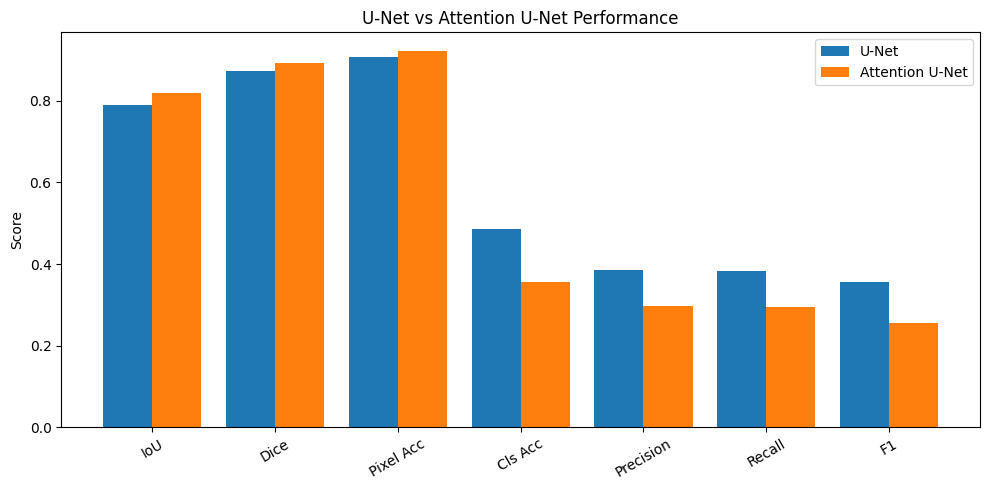


===== Summary =====
IoU: Attention U-Net performs better
Dice: Attention U-Net performs better
Pixel Acc: Attention U-Net performs better
Cls Acc: U-Net performs better
Precision: U-Net performs better
Recall: U-Net performs better
F1: U-Net performs better


In [ ]:
# ================================
# Step 16: Compare U-Net vs Attention U-Net
# ================================

import pandas as pd

# -------------------------------
# Collect metrics
# -------------------------------
comparison_data = {
    "Metric": ["IoU", "Dice", "Pixel Acc", "Cls Acc", "Precision", "Recall", "F1"],

    "U-Net (Test)": [
        test_metrics["IoU"],
        test_metrics["Dice"],
        test_metrics["Pixel Acc"],
        test_metrics["Cls Acc"],
        test_metrics["Precision"],
        test_metrics["Recall"],
        test_metrics["F1"]
    ],

    "Attention U-Net (Test)": [
        att_test_metrics["IoU"],
        att_test_metrics["Dice"],
        att_test_metrics["Pixel Acc"],
        att_test_metrics["Cls Acc"],
        att_test_metrics["Precision"],
        att_test_metrics["Recall"],
        att_test_metrics["F1"]
    ]
}

df = pd.DataFrame(comparison_data)

print("\n===== Model Comparison (Test Set) =====")
print(df)


# -------------------------------
# Visualization (Bar Chart)
# -------------------------------
import matplotlib.pyplot as plt

metrics = df["Metric"]
unet_vals = df["U-Net (Test)"]
att_vals = df["Attention U-Net (Test)"]

x = range(len(metrics))

plt.figure(figsize=(10,5))
plt.bar(x, unet_vals, width=0.4, label="U-Net", align="center")
plt.bar([i + 0.4 for i in x], att_vals, width=0.4, label="Attention U-Net", align="center")

plt.xticks([i + 0.2 for i in x], metrics, rotation=30)
plt.ylabel("Score")
plt.title("U-Net vs Attention U-Net Performance")
plt.legend()

plt.tight_layout()
plt.show()


# -------------------------------
# Simple Conclusion Print
# -------------------------------
print("\n===== Summary =====")

for metric in metrics:
    u = df[df["Metric"] == metric]["U-Net (Test)"].values[0]
    a = df[df["Metric"] == metric]["Attention U-Net (Test)"].values[0]

    better = "Attention U-Net" if a > u else "U-Net"

    print(f"{metric}: {better} performs better")

BONUS 1: Try Different Classifier Heads
(MobileNet / EfficientNet / DenseNet)

In [ ]:
# ================================
# BONUS 1: Try Different Classifier Heads
# (MobileNet / EfficientNet / DenseNet)
# ================================

import torch
import torch.nn as nn
import torchvision.models as models
# Removed specific _Weights imports

# -------------------------------
# Generic U-Net + External Classifier
# -------------------------------
class UNetWithBackboneClassifier(nn.Module):
    def __init__(self, num_classes, backbone="mobilenet"):
        super().__init__()

        # ---------- U-Net Encoder ----------
        self.inc = DoubleConv(3, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.bottleneck = Down(512, 1024)

        # ---------- Decoder ----------
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)
        self.seg_head = nn.Conv2d(64, 1, kernel_size=1)

        # ---------- Choose classifier backbone ----------
        self.backbone_name = backbone

        if backbone == "mobilenet":
            # Using pretrained=True for broader compatibility
            self.classifier = models.mobilenet_v2(pretrained=True)
            self.classifier.classifier[1] = nn.Linear(1280, num_classes)

        elif backbone == "efficientnet":
            # Using pretrained=True for broader compatibility
            self.classifier = models.efficientnet_b0(pretrained=True)
            self.classifier.classifier[1] = nn.Linear(1280, num_classes)

        elif backbone == "densenet":
            # Using pretrained=True for broader compatibility
            self.classifier = models.densenet121(pretrained=True)
            self.classifier.classifier = nn.Linear(1024, num_classes)

        else:
            raise ValueError("Unsupported backbone")

    def forward(self, x):
        # ---------- Encoder ----------
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.bottleneck(x4)

        # ---------- Classification (use original image for pretrained nets) ----------
        cls_out = self.classifier(x)

        # ---------- Decoder ----------
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        seg_out = self.seg_head(x)

        return seg_out, cls_out


# ================================
# Train Different Classifiers
# ================================

backbones = ["mobilenet", "efficientnet", "densenet"]
results = {}

for backbone in backbones:
    print(f"\n🔹 Training with {backbone.upper()}")

    model_b = UNetWithBackboneClassifier(
        num_classes=len(dataset.classes),
        backbone=backbone
    ).to(device)

    optimizer = torch.optim.Adam(model_b.parameters(), lr=5e-5)

    # Train few epochs (keep small for comparison)
    for epoch in range(5):
        train_loss, train_acc = train_one_epoch(model_b, train_loader, optimizer)
        val_loss, val_acc = validate(model_b, val_loader)

        print(f"{backbone} Epoch {epoch+1} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    # Evaluate
    metrics = evaluate(model_b, test_loader, len(dataset.classes))
    results[backbone] = metrics["Cls Acc"]


# ================================
# Compare Results
# ================================

print("\n===== Classifier Comparison =====")
for k, v in results.items():
    print(f"{k}: {v:.4f}")

best_model = max(results, key=results.get)
print(f"\n🏆 Best Classifier: {best_model}")


🔹 Training with MOBILENET


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 130MB/s]
100%|██████████| 81/81 [01:49<00:00,  1.35s/it]


mobilenet Epoch 1 | Train Acc: 0.3540 | Val Acc: 0.6521


...

densenet Epoch 3 | Train Acc: 0.9027 | Val Acc: 0.8436


100%|██████████| 81/81 [01:54<00:00,  1.41s/it]


densenet Epoch 4 | Train Acc: 0.9527 | Val Acc: 0.8620


100%|██████████| 81/81 [01:53<00:00,  1.41s/it]


densenet Epoch 5 | Train Acc: 0.9796 | Val Acc: 0.8696

===== Classifier Comparison =====
mobilenet: 0.8445
efficientnet: 0.7957
densenet: 0.8793

🏆 Best Classifier: densenet


BONUS 2: Data Augmentation Study

DEBUG: Loaded 7390 .jpg files from dataset/images
DEBUG: Loaded 7390 .jpg files from dataset/images

🚫 Training WITHOUT Augmentation


100%|██████████| 81/81 [01:37<00:00,  1.21s/it]


Epoch 1 | Train Acc: 0.0804 | Val Acc: 0.0922


100%|██████████| 81/81 [01:37<00:00,  1.20s/it]


Epoch 2 | Train Acc: 0.1480 | Val Acc: 0.1819

✅ Training WITH Augmentation


100%|██████████| 81/81 [01:49<00:00,  1.36s/it]


Epoch 1 | Train Acc: 0.0694 | Val Acc: 0.0878


100%|██████████| 81/81 [01:49<00:00,  1.35s/it]


Epoch 2 | Train Acc: 0.1169 | Val Acc: 0.1262

===== AUGMENTATION COMPARISON =====
IoU:
  Without Aug: 0.7185
  With Aug   : 0.6777

Dice:
  Without Aug: 0.8251
  With Aug   : 0.7947

Pixel Acc:
  Without Aug: 0.8631
  With Aug   : 0.8317

Cls Acc:
  Without Aug: 0.1999
  With Aug   : 0.1443

Precision:
  Without Aug: 0.1031
  With Aug   : 0.0718

Recall:
  Without Aug: 0.1561
  With Aug   : 0.1036

F1:
  Without Aug: 0.1063
  With Aug   : 0.0719



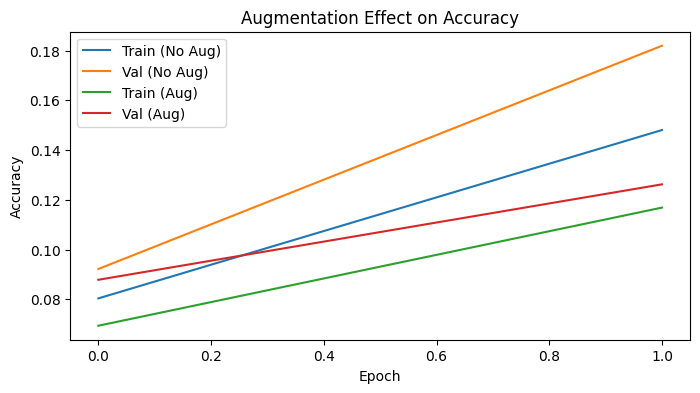

In [ ]:
# ================================
# BONUS 2: Data Augmentation Study
# ================================

import copy
import matplotlib.pyplot as plt

# -------------------------------
# Create TWO datasets
# -------------------------------

# WITHOUT augmentation
dataset_no_aug = OxfordPetDataset(
    "dataset/images",
    "dataset/masks",
    joint_transform=JointTransform(augment=False)
)

# WITH augmentation
dataset_aug = OxfordPetDataset(
    "dataset/images",
    "dataset/masks",
    joint_transform=JointTransform(augment=True)
)


# -------------------------------
# SAME SPLIT (VERY IMPORTANT)
# -------------------------------

torch.manual_seed(42)

total_size = len(dataset_no_aug)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

# Split indices ONCE
indices = torch.randperm(total_size)

train_idx = indices[:train_size]
val_idx = indices[train_size:train_size+val_size]
test_idx = indices[train_size+val_size:]


from torch.utils.data import Subset

train_no_aug = Subset(dataset_no_aug, train_idx)
val_no_aug   = Subset(dataset_no_aug, val_idx)
test_no_aug  = Subset(dataset_no_aug, test_idx)

train_aug = Subset(dataset_aug, train_idx)
val_aug   = Subset(dataset_aug, val_idx)
test_aug  = Subset(dataset_aug, test_idx)


# -------------------------------
# DataLoaders
# -------------------------------
train_loader_no_aug = DataLoader(train_no_aug, batch_size=64, shuffle=True, num_workers=0)
val_loader_no_aug   = DataLoader(val_no_aug, batch_size=64, shuffle=False, num_workers=0)
test_loader_no_aug  = DataLoader(test_no_aug, batch_size=64, shuffle=False, num_workers=0)

train_loader_aug = DataLoader(train_aug, batch_size=64, shuffle=True, num_workers=0)
val_loader_aug   = DataLoader(val_aug, batch_size=64, shuffle=False, num_workers=0)
test_loader_aug  = DataLoader(test_aug, batch_size=64, shuffle=False, num_workers=0)


# -------------------------------
# Training Function (Reusable)
# -------------------------------
def train_model(model, train_loader, val_loader, epochs=2):
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)

    train_accs, val_accs = [], []

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = validate(model, val_loader)

        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Epoch {epoch+1} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    return train_accs, val_accs


# -------------------------------
# Train WITHOUT Augmentation
# -------------------------------
print("\n🚫 Training WITHOUT Augmentation")
model_no_aug = UNetWithClassifier(len(dataset.classes)).to(device)

train_acc_no_aug, val_acc_no_aug = train_model(
    model_no_aug, train_loader_no_aug, val_loader_no_aug
)

metrics_no_aug = evaluate(model_no_aug, test_loader_no_aug, len(dataset.classes))


# -------------------------------
# Train WITH Augmentation
# -------------------------------
print("\n✅ Training WITH Augmentation")
model_aug = UNetWithClassifier(len(dataset.classes)).to(device)

train_acc_aug, val_acc_aug = train_model(
    model_aug, train_loader_aug, val_loader_aug
)

metrics_aug = evaluate(model_aug, test_loader_aug, len(dataset.classes))


# -------------------------------
# Compare Results
# -------------------------------
print("\n===== AUGMENTATION COMPARISON =====")

for key in metrics_no_aug.keys():
    print(f"{key}:")
    print(f"  Without Aug: {metrics_no_aug[key]:.4f}")
    print(f"  With Aug   : {metrics_aug[key]:.4f}")
    print("")


# -------------------------------
# Plot Accuracy Comparison
# -------------------------------
plt.figure(figsize=(8,4))

plt.plot(train_acc_no_aug, label="Train (No Aug)")
plt.plot(val_acc_no_aug, label="Val (No Aug)")

plt.plot(train_acc_aug, label="Train (Aug)")
plt.plot(val_acc_aug, label="Val (Aug)")

plt.legend()
plt.title("Augmentation Effect on Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.show()

BONUS 3: 3-Class Segmentation
(Background / Pet / Boundary)

In [ ]:
# ================================
# BONUS 3: 3-Class Segmentation
# (Background / Pet / Boundary)
# ================================

import numpy as np
import torch
import torch.nn as nn

# --------------------------------
# 1. Update Dataset (3-class mask)
# --------------------------------
class OxfordPetDataset3Class(Dataset):
    def __init__(self, image_dir, mask_dir, joint_transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.joint_transform = joint_transform

        self.image_files = sorted([
            f for f in os.listdir(image_dir) if f.endswith(".jpg")
        ])

        self.classes = sorted(list(set([f.split('_')[0] for f in self.image_files])))
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]

        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, img_name.replace(".jpg", ".png"))

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # ORIGINAL LABELS:
        # 1 = pet
        # 2 = background
        # 3 = boundary

        mask = np.array(mask)

        # Convert to 3-class:
        # background -> 0
        # pet -> 1
        # boundary -> 2
        new_mask = np.zeros_like(mask)
        new_mask[mask == 1] = 1
        new_mask[mask == 3] = 2

        mask = Image.fromarray(new_mask.astype(np.uint8))

        # Label
        class_name = img_name.split('_')[0]
        label = self.class_to_idx[class_name]

        if self.joint_transform:
            image, mask = self.joint_transform(image, mask)

        return image, mask.long(), label


# --------------------------------
# 2. Update Transform (IMPORTANT)
# --------------------------------
class JointTransform3Class(JointTransform):
    def __call__(self, image, mask):
        image, mask = super().__call__(image, mask)

        # mask is float → convert to long class labels
        mask = mask.squeeze().long()   # shape (H,W)

        return image, mask


# --------------------------------
# 3. Update Model Output
# --------------------------------
class UNet3Class(UNetWithClassifier):
    def __init__(self, num_classes):
        super().__init__(num_classes)

        # Change segmentation head to 3 classes
        self.seg_head = nn.Conv2d(64, 3, kernel_size=1)


# --------------------------------
# 4. Loss Functions
# --------------------------------

# Segmentation → CrossEntropyLoss (multi-class)
seg_loss_fn_3class = nn.CrossEntropyLoss()

# Classification (same)
cls_loss_fn = nn.CrossEntropyLoss()

def total_loss_3class(seg_pred, seg_target, cls_pred, cls_target):
    # seg_pred: (B,3,H,W)
    # seg_target: (B,H,W)
    seg_loss = seg_loss_fn_3class(seg_pred, seg_target)

    cls_loss = cls_loss_fn(cls_pred, cls_target)

    return seg_loss + cls_loss, seg_loss, cls_loss


# --------------------------------
# 5. Quick Test
# --------------------------------
dataset_3c = OxfordPetDataset3Class(
    "dataset/images",
    "dataset/masks",
    joint_transform=JointTransform3Class(augment=True)
)

img, mask, label = dataset_3c[0]

print("Image shape:", img.shape)
print("Mask shape:", mask.shape)
print("Mask unique values:", torch.unique(mask))  # should be [0,1,2]


# --------------------------------
# 6. Model Test
# --------------------------------
model_3c = UNet3Class(len(dataset.classes)).to(device)

x = torch.randn(2, 3, 224, 224).to(device)
seg_out, cls_out = model_3c(x)

print("Segmentation output:", seg_out.shape)  # (B,3,H,W)
print("Classification output:", cls_out.shape)

Image shape: torch.Size([3, 128, 128])
Mask shape: torch.Size([128, 128])
Mask unique values: tensor([0, 1, 2])
Segmentation output: torch.Size([2, 3, 224, 224])
Classification output: torch.Size([2, 35])


BONUS 4: Hyperparameter Tuning

In [ ]:
# ================================
# BONUS 4: Hyperparameter Tuning
# ================================
# hyperparameter tuning to find the best training setup
import itertools
import pandas as pd

# -------------------------------
# Hyperparameter Search Space
# -------------------------------
learning_rates = [1e-3, 1e-4]
optimizers_list = ["adam", "sgd"]
batch_sizes = [16, 32]

results = []

# -------------------------------
# Helper: get optimizer
# -------------------------------
def get_optimizer(name, model, lr):
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    else:
        raise ValueError("Unknown optimizer")


# -------------------------------
# Loop over all combinations
# -------------------------------
for lr, opt_name, bs in itertools.product(learning_rates, optimizers_list, batch_sizes):

    print(f"\n🔹 Testing: LR={lr}, Optimizer={opt_name}, Batch Size={bs}")

    # Create fresh model
    model_tune = UNetWithClassifier(len(dataset.classes)).to(device)

    # DataLoader with new batch size
    train_loader_tune = DataLoader(train_dataset, batch_size=bs, shuffle=True, num_workers=0)
    val_loader_tune   = DataLoader(val_dataset, batch_size=bs, shuffle=False, num_workers=0)

    optimizer = get_optimizer(opt_name, model_tune, lr)

    # Train few epochs (short run)
    best_val_acc = 0

    for epoch in range(2):   # keep small for speed
        train_loss, train_acc = train_one_epoch(model_tune, train_loader_tune, optimizer)
        val_loss, val_acc = validate(model_tune, val_loader_tune)

        print(f"Epoch {epoch+1} | Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc

    # Save results
    results.append({
        "Learning Rate": lr,
        "Optimizer": opt_name,
        "Batch Size": bs,
        "Best Val Acc": best_val_acc
    })


# -------------------------------
# Convert to DataFrame
# -------------------------------
df_results = pd.DataFrame(results)

print("\n===== Hyperparameter Results =====")
print(df_results)


# -------------------------------
# Find Best Combination
# -------------------------------
best_row = df_results.loc[df_results["Best Val Acc"].idxmax()]

print("\n🏆 BEST CONFIGURATION:")
print(best_row)


# -------------------------------
# Optional: Sort results
# -------------------------------
df_sorted = df_results.sort_values(by="Best Val Acc", ascending=False)

print("\n===== Sorted Results =====")
print(df_sorted)


🔹 Testing: LR=0.001, Optimizer=adam, Batch Size=16


100%|██████████| 324/324 [01:38<00:00,  3.28it/s]


Epoch 1 | Val Acc: 0.0545


100%|██████████| 324/324 [01:38<00:00,  3.30it/s]


Epoch 2 | Val Acc: 0.0643

🔹 Testing: LR=0.001, Optimizer=adam, Batch Size=32


...

Epoch 2 | Val Acc: 0.0688

🔹 Testing: LR=0.0001, Optimizer=sgd, Batch Size=32


100%|██████████| 162/162 [01:33<00:00,  1.72it/s]


Epoch 1 | Val Acc: 0.0607


100%|██████████| 162/162 [01:33<00:00,  1.72it/s]


Epoch 2 | Val Acc: 0.0652

===== Hyperparameter Results =====
   Learning Rate Optimizer  Batch Size  Best Val Acc
0         0.0010      adam          16      0.064286
1         0.0010      adam          32      0.056786
2         0.0010       sgd          16      0.104464
3         0.0010       sgd          32      0.093929
4         0.0001      adam          16      0.131250
5         0.0001      adam          32      0.161607
6         0.0001       sgd          16      0.068750
7         0.0001       sgd          32      0.065179

🏆 BEST CONFIGURATION:
Learning Rate      0.0001
Optimizer            adam
Batch Size             32
Best Val Acc     0.161607
Name: 5, dtype: object

===== Sorted Results =====
   Learning Rate Optimizer  Batch Size  Best Val Acc
5         0.0001      adam          32      0.161607
4         0.0001      adam          16      0.131250
2         0.0010       sgd          16      0.104464
3         0.0010       sgd          32      0.093929
6         0.0001  

BONUS 5: U-Net + EfficientDet-style Decoder (BiFPN)

In [ ]:
# ================================
# BONUS 5: U-Net + EfficientDet-style Decoder (BiFPN)
# ================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# -------------------------------
# Basic Conv Block
# -------------------------------
class ConvBNReLU(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, s, p, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# -------------------------------
# Encoder (same as U-Net)
# -------------------------------
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.inc = DoubleConv(3, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        return x1, x2, x3, x4, x5


# -------------------------------
# BiFPN-like Fusion Block
# -------------------------------
class BiFPN(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv3 = ConvBNReLU(channels, channels)
        self.conv4 = ConvBNReLU(channels, channels)
        self.conv5 = ConvBNReLU(channels, channels)

        # Learnable weights
        self.w1 = nn.Parameter(torch.ones(2))
        self.w2 = nn.Parameter(torch.ones(2))

    def forward(self, p3, p4, p5):
        w1 = torch.softmax(self.w1, dim=0)
        w2 = torch.softmax(self.w2, dim=0)

        # Top-down
        p4_td = self.conv4(w1[0]*p4 + w1[1]*F.interpolate(p5, scale_factor=2, mode='nearest'))
        p3_td = self.conv3(w2[0]*p3 + w2[1]*F.interpolate(p4_td, scale_factor=2, mode='nearest'))

        return p3_td, p4_td, p5


# -------------------------------
# Efficient U-Net Model
# -------------------------------
class EfficientUNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.encoder = Encoder()

        # Reduce channels for BiFPN
        self.reduce3 = nn.Conv2d(256, 256, 1)
        self.reduce4 = nn.Conv2d(512, 256, 1)
        self.reduce5 = nn.Conv2d(1024, 256, 1)

        self.bifpn = BiFPN(256)

        # Final segmentation head
        self.seg_head = nn.Conv2d(256, 1, kernel_size=1)

        # Classification head
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)),
            nn.Flatten(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x1, x2, x3, x4, x5 = self.encoder(x)

        # Classification from bottleneck
        cls_out = self.classifier(x5)

        # Reduce channels
        p3 = self.reduce3(x3)
        p4 = self.reduce4(x4)
        p5 = self.reduce5(x5)

        # BiFPN fusion
        p3, p4, p5 = self.bifpn(p3, p4, p5)

        # Upsample to original size
        out = F.interpolate(p3, scale_factor=4, mode='bilinear', align_corners=False)

        seg_out = self.seg_head(out)

        return seg_out, cls_out


# ================================
# Test Model
# ================================

model_eff = EfficientUNet(len(dataset.classes)).to(device)

x = torch.randn(2, 3, 224, 224).to(device)
seg_out, cls_out = model_eff(x)

print("Seg shape:", seg_out.shape)   # (B,1,H,W)
print("Cls shape:", cls_out.shape)

In [ ]:
# ================================
# BONUS 5: Efficient U-Net
# ================================

import torch
import torch.nn.functional as F
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt


# ================================
# Step 1: Initialize Model
# ================================
model_eff = EfficientUNet(len(dataset.classes)).to(device)
optimizer = torch.optim.Adam(model_eff.parameters(), lr=5e-5)

num_epochs = 3


# ================================
# Step 2: Train Model
# ================================
train_losses_eff = []
val_losses_eff = []
train_accs_eff = []
val_accs_eff = []

for epoch in range(num_epochs):
    print(f"\n[Efficient U-Net] Epoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(model_eff, train_loader, optimizer)
    val_loss, val_acc = validate(model_eff, val_loader)

    train_losses_eff.append(train_loss)
    val_losses_eff.append(val_loss)
    train_accs_eff.append(train_acc)
    val_accs_eff.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")


# ================================
# Step 3: Plot Curves
# ================================
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_losses_eff, label="Train Loss")
plt.plot(val_losses_eff, label="Val Loss")
plt.legend()
plt.title("Efficient U-Net Loss")

plt.subplot(1,2,2)
plt.plot(train_accs_eff, label="Train Acc")
plt.plot(val_accs_eff, label="Val Acc")
plt.legend()
plt.title("Efficient U-Net Accuracy")

plt.show()


# ================================
# Step 4: Evaluate
# ================================
metrics_eff = evaluate(model_eff, test_loader, len(dataset.classes))
print_metrics("Efficient U-Net Test", metrics_eff)


# ================================
# Step 5: Final Comparison (3 models)
# ================================
print("\n===== FINAL COMPARISON =====")

for metric in test_metrics.keys():
    print(f"{metric}:")
    print(f"  U-Net           : {test_metrics[metric]:.4f}")
    print(f"  Attention U-Net : {att_test_metrics[metric]:.4f}")
    print(f"  Efficient U-Net : {metrics_eff[metric]:.4f}")
    print("")

Step 17: Run Model on Random Images (Dynamic Testing)


===== U-Net Random Testing =====

🔹 Testing on index: 2358


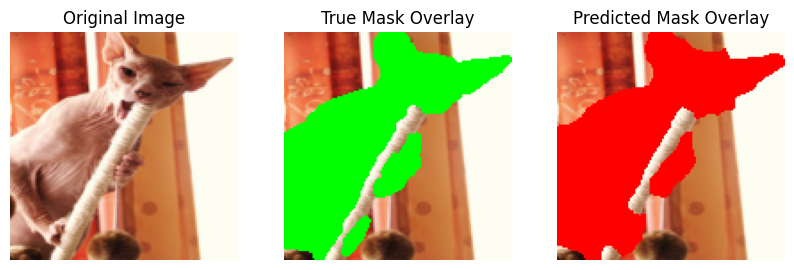

True Class: Sphynx
Predicted Class: Sphynx
IoU Score: 0.9153

🔹 Testing on index: 1968


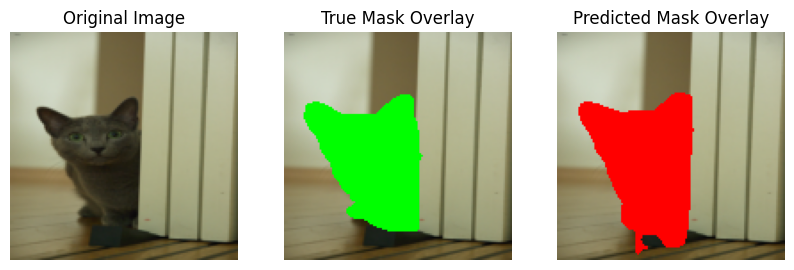

True Class: Russian
Predicted Class: British
IoU Score: 0.8600

🔹 Testing on index: 4187


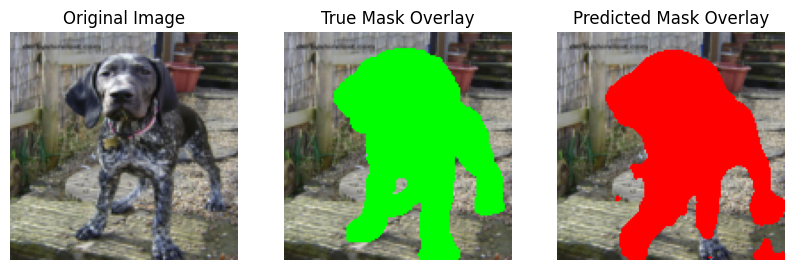

True Class: german
Predicted Class: english
IoU Score: 0.7990

===== Attention U-Net Random Testing =====

🔹 Testing on index: 3184


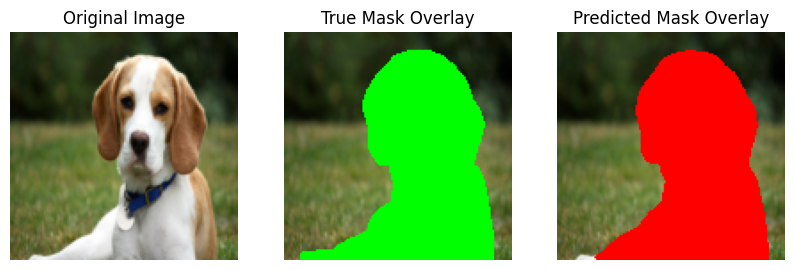

True Class: beagle
Predicted Class: beagle
IoU Score: 0.9679

🔹 Testing on index: 662


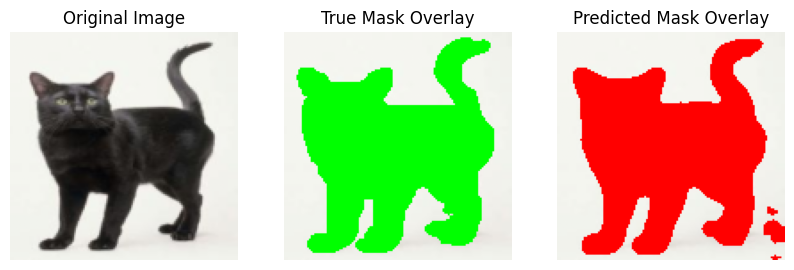

True Class: Bombay
Predicted Class: Bombay
IoU Score: 0.9074

🔹 Testing on index: 3857


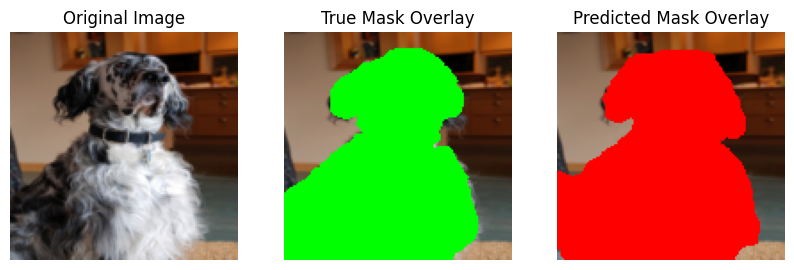

True Class: english
Predicted Class: japanese
IoU Score: 0.9088

===== Efficient U-Net Random Testing =====
Efficient model not available


In [ ]:
# ================================
# Step 17: Run Model on Random Images (Dynamic Testing)
# ================================

import random

def test_random_samples(model, dataset, num_samples=5):
    model.eval()

    indices = random.sample(range(len(dataset)), num_samples)

    for idx in indices:
        print(f"\n🔹 Testing on index: {idx}")
        predict_and_visualize(model, dataset, idx)


# ================================
# Run on U-Net
# ================================
print("\n===== U-Net Random Testing =====")
test_random_samples(model, dataset_no_aug, num_samples=3)


# ================================
# Run on Attention U-Net
# ================================
print("\n===== Attention U-Net Random Testing =====")
test_random_samples(model_att, dataset_no_aug, num_samples=3)


# ================================
# (Optional) Run on Efficient U-Net
# ================================
try:
    print("\n===== Efficient U-Net Random Testing =====")
    test_random_samples(model_eff, dataset_no_aug, num_samples=3)
except:
    print("Efficient model not available")


Step 18: Save FINAL Models (NO TRAINING HERE)


In [ ]:
# ================================
# Step 18: Save FINAL Models (NO TRAINING HERE)
# ================================

import torch
import os

# Define model-specific directories within the base_drive_dir
unet_dir = os.path.join(base_drive_dir, 'unet_checkpoints')
attention_unet_dir = os.path.join(base_drive_dir, 'attention_unet_checkpoints')
efficient_unet_dir = os.path.join(base_drive_dir, 'efficient_unet_checkpoints')

os.makedirs(unet_dir, exist_ok=True)
os.makedirs(attention_unet_dir, exist_ok=True)
os.makedirs(efficient_unet_dir, exist_ok=True)

# -------------------------------
# Save final trained model
# -------------------------------
torch.save(model.state_dict(), os.path.join(unet_dir, "unet_final.pth"))

print("✅ U-Net saved to Google Drive!")


# -------------------------------
# Save Attention U-Net (if exists)
# -------------------------------
try:
    torch.save(model_att.state_dict(), os.path.join(attention_unet_dir, "attention_unet.pth"))
    print("✅ Attention U-Net saved to Google Drive!")
except:
    print("⚠️ Attention model not found, skipping save to Drive.")


# -------------------------------
# Save Efficient model (if exists)
# -------------------------------
try:
    torch.save(model_eff.state_dict(), os.path.join(efficient_unet_dir, "efficient_unet.pth"))
    print("✅ Efficient U-Net saved to Google Drive!")
except:
    print("⚠️ Efficient model not found, skipping save to Drive.")


# -------------------------------
# Best model already saved in Step 11
# -------------------------------
# The best_model_path for the base UNet was already updated in Step 11.
# This now refers to the Google Drive location where it was saved during training.
print(f"📌 Best U-Net model from training (based on validation accuracy) was saved to: {os.path.join(unet_dir, 'best_model.pth')}")
print(f"📌 Best Attention U-Net model from training was saved to: {os.path.join(attention_unet_dir, 'attention_best.pth')}")

✅ U-Net saved to Google Drive!
✅ Attention U-Net saved to Google Drive!
⚠️ Efficient model not found, skipping save to Drive.
📌 Best U-Net model from training (based on validation accuracy) was saved to: /content/drive/MyDrive/segmentation_project/unet_checkpoints/best_model.pth
📌 Best Attention U-Net model from training was saved to: /content/drive/MyDrive/segmentation_project/attention_unet_checkpoints/attention_best.pth


Step 19: Load & Test Model

✅ Model loaded successfully!


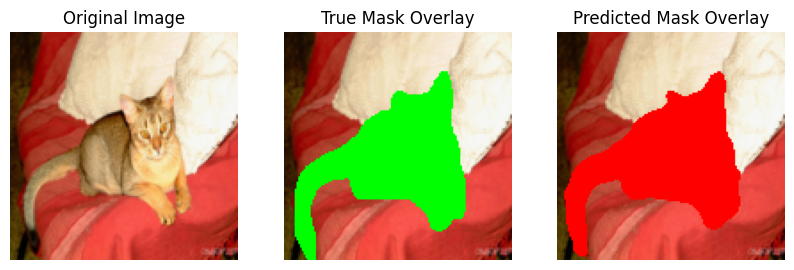

True Class: Abyssinian
Predicted Class: Abyssinian
IoU Score: 0.9380

🔹 Testing on index: 7379


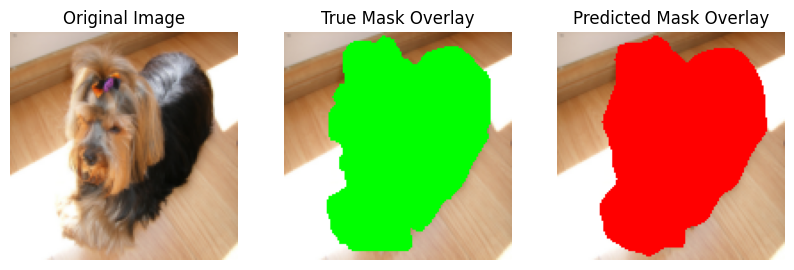

True Class: yorkshire
Predicted Class: yorkshire
IoU Score: 0.9607

🔹 Testing on index: 4670


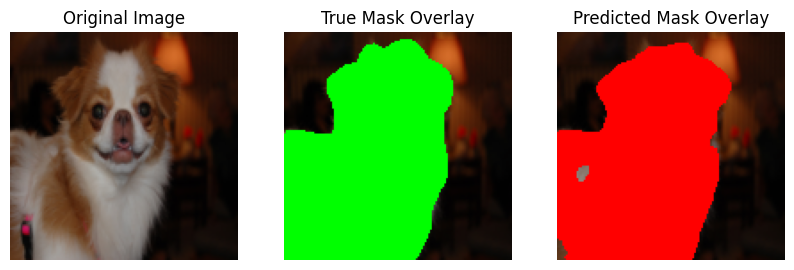

True Class: japanese
Predicted Class: japanese
IoU Score: 0.9590

🔹 Testing on index: 5211


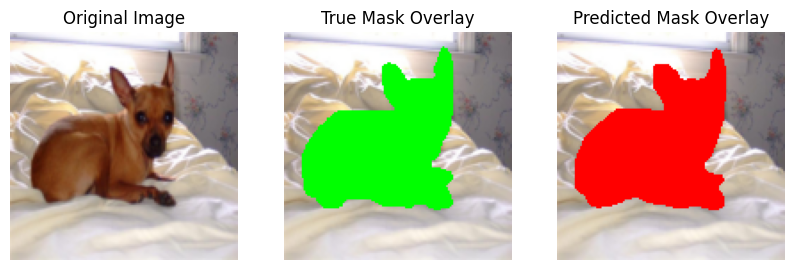

True Class: miniature
Predicted Class: miniature
IoU Score: 0.9537

===== Loaded Model Test Metrics =====
IoU: 0.7903
Dice: 0.8726
Pixel Acc: 0.9086
Cls Acc: 0.4849
Precision: 0.3851
Recall: 0.3826
F1: 0.3561


In [ ]:
# ================================
# Step 19: Load & Test Model
# ================================

import torch

# -------------------------------
# Load BEST Model
# -------------------------------
model_loaded = UNetWithClassifier(num_classes=len(dataset.classes)).to(device)

model_path = os.path.join(SAVE_DIR, "unet_best.pth")

model_loaded.load_state_dict(torch.load(model_path, map_location=device))
model_loaded.eval()

print("✅ Model loaded successfully!")


# -------------------------------
# Test on Single Image
# -------------------------------
predict_and_visualize(model_loaded, dataset_no_aug, idx=5)


# -------------------------------
# Test on Multiple Random Images
# -------------------------------
test_random_samples(model_loaded, dataset_no_aug, num_samples=3)


# -------------------------------
# Evaluate Loaded Model
# -------------------------------
loaded_metrics = evaluate(model_loaded, test_loader, len(dataset.classes))

print("\n===== Loaded Model Test Metrics =====")
for k, v in loaded_metrics.items():
    print(f"{k}: {v:.4f}")

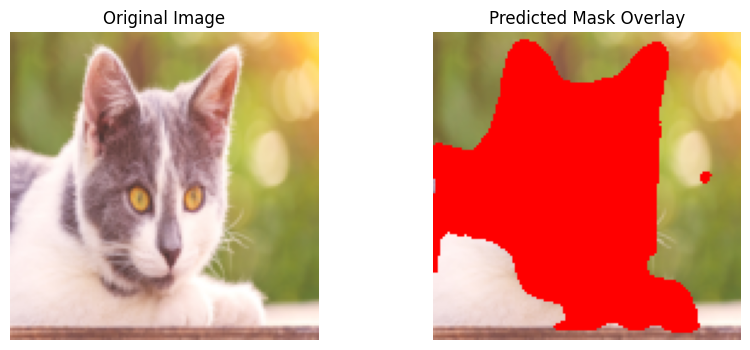

Predicted Class: Sphynx


In [ ]:
# ================================
# Test on  Image
# ================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


img_path = "/content/test.jpg"

# -------------------------------
# Load Image
# -------------------------------
image = Image.open(img_path).convert("RGB")


# -------------------------------
# Use SAME transform (NO AUGMENTATION)
# -------------------------------
transform = JointTransform(augment=False)

# Dummy mask (required for transform)
dummy_mask = Image.fromarray(
    np.zeros((image.size[1], image.size[0]), dtype=np.uint8)
)

img_t, _ = transform(image, dummy_mask)


# -------------------------------
# Prepare Input
# -------------------------------
img_input = img_t.unsqueeze(0).to(device)


# -------------------------------
# Run Model (Inference)
# -------------------------------
model_loaded.eval()

with torch.no_grad():
    seg_pred, cls_pred = model_loaded(img_input)


# -------------------------------
# Process Segmentation Output
# -------------------------------
pred_mask = torch.sigmoid(seg_pred).cpu().squeeze().numpy()
pred_mask = (pred_mask > 0.5).astype(np.uint8)


# -------------------------------
# Process Classification Output
# -------------------------------
pred_class = torch.argmax(cls_pred, dim=1).item()
pred_class_name = dataset.classes[pred_class]


# -------------------------------
# Denormalize Image
# -------------------------------
def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (img * std + mean).clamp(0,1)

img_vis = denormalize(img_t).permute(1,2,0).cpu().numpy()


# -------------------------------
# Create Overlay
# -------------------------------
overlay = img_vis.copy()
overlay[pred_mask > 0.5] = [1, 0, 0]   # red mask


# -------------------------------
# Show Results
# -------------------------------
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(img_vis)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(overlay)
plt.title("Predicted Mask Overlay")
plt.axis("off")

plt.show()


# -------------------------------
# Print Prediction
# -------------------------------
print("Predicted Class:", pred_class_name)